<center><h1>Ngo_Jesse_HW3</h1></center>
<br>
<br>

Name: Jesse Ngo
<br>
Github Username: hjngo
<br>
USC ID: 4722249405

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download the AReM Data

Package imports

In [8]:
# Imports

import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

**Data Cleaning** 

A few files needed minor cleaning, which was done directly in the data files in `../data/AReM`:

| File | Problem | Fix (in the file) |
|---|---|---|
| bending2/dataset4.csv | values were separated by spaces instead of commas | replaced the spaces with commas |
| cycling/dataset9.csv, cycling/dataset14.csv | the last row had a trailing comma (an empty 8th field) | removed the trailing comma |
| sitting/dataset8.csv | only 479 rows | left as is |

In [9]:
# Question 1a

# Make sure path exists
dataPath = Path("..") / "data" / "AReM"
if not dataPath.exists():
    raise FileNotFoundError(f"Couldn't find {dataPath.resolve()}. The current working directory is {Path.cwd()} "
                            "-- it should be the folder this notebook is in.")

SERIES = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
COLUMNS = ["time"] + SERIES

def dataset_number(path):
    return int(re.search(r"\d+", path.stem).group())

instances = []   # one entry per file: activity, dataset number, DataFrame

for folder in sorted(p for p in dataPath.iterdir() if p.is_dir()):
    for file in sorted(folder.glob("dataset*.csv"), key=dataset_number):
        df = pd.read_csv(file, skiprows=5, header=None, names=COLUMNS)
        instances.append({"activity": folder.name,
                          "dataset": dataset_number(file),
                          "data": df})

# print(f"Instances loaded: {len(instances)}")

instances[0]["data"].head()

,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0,39.25,0.43,22.75,0.43,33.75,1.3
1,250,39.25,0.43,23.00,0.00,33.00,0.0
2,500,39.25,0.43,23.25,0.43,33.00,0.0
3,750,39.50,0.50,23.00,0.71,33.00,0.0
4,1000,39.50,0.50,24.00,0.00,33.00,0.0


### (b) Train/Test Split

Datasets 1 and 2 in `bending1` and `bending2`, and datasets 1, 2 and 3 in every other folder, are the test set. Everything else is the training set.

In [3]:
# Question 1b

# Check's if activity is bending1 and bending2, only return true if datasets 1,2. 
# If any other activity, then return true if datasets 1,2,3. 
# Everything else returns false
def is_test(activity, dataset):
    if activity in ("bending1", "bending2"):
        return dataset in (1, 2)
    return dataset in (1, 2, 3)

# Set instances to be test/train
for inst in instances:
    inst["set"] = "test" if is_test(inst["activity"], inst["dataset"]) else "train"

# Verification Count
split = (pd.DataFrame([(i["activity"], i["set"]) for i in instances], columns=["activity", "set"])
           .value_counts().unstack(fill_value=0)[["train", "test"]])
split.loc["Total"] = split.sum()
split

set,train,test
activity,,
bending1,5,2
bending2,4,2
cycling,12,3
lying,12,3
sitting,12,3
standing,12,3
walking,12,3
Total,69,19


This gives **69 training** and **19 test** instances (88 in total).

### (c) Feature Extraction

#### i. Time-domain features used in time series classification

Time-domain features are computed directly from the raw values of the series (as opposed to frequency-domain features such as FFT coefficients or wavelet energies). The ones most commonly used in time series and sensor/activity-recognition classification are:

**Location / central tendency**
- Mean, median, mode
- Trimmed mean

**Extremes and order statistics**
- Minimum, maximum
- Range (max − min)
- Quartiles / percentiles (1st quartile, 3rd quartile, 5th/95th percentiles, …)
- Interquartile range (Q3 − Q1)

**Spread / variability**
- Variance and standard deviation
- Mean absolute deviation, median absolute deviation
- Coefficient of variation (std / mean)

**Shape of the distribution**
- Skewness (asymmetry)
- Kurtosis (tailedness / peakedness)

**Energy and magnitude**
- Root mean square (RMS)
- Signal energy (sum of squares) and signal power
- Sum of absolute values / signal magnitude area

**Temporal dynamics (order-dependent)**
- Zero-crossing rate and mean-crossing rate
- Autocorrelation at a given lag
- Slope / linear trend over the window
- Mean and std of the first difference (mean absolute change, sum of absolute changes)
- Number of peaks, peak-to-peak amplitude, time between peaks
- Number of values above/below the mean, longest strike above/below the mean
- Sample entropy / approximate entropy (regularity)

#### ii. Extract min, max, mean, median, std, 1st quartile, 3rd quartile

The features are left **unnormalized**. Normalizing would not change the shape of each feature's distribution, and for part iii it would make the result meaningless: after standardization every feature's standard deviation is exactly 1.

In [4]:
# Question 1cii
STATS = {
    "min":       np.min,
    "max":       np.max,
    "mean":      np.mean,
    "median":    np.median,
    "std":       lambda x: np.std(x, ddof=1),
    "1st_quart": lambda x: np.percentile(x, 25),
    "3rd_quart": lambda x: np.percentile(x, 75),
}

def extract_features(inst):
    row = {}
    for i, series in enumerate(SERIES, start=1):
        x = inst["data"][series].to_numpy()
        for name, f in STATS.items():
            row[f"{name}{i}"] = f(x)
    return row

features = pd.DataFrame([extract_features(i) for i in instances])
features.insert(0, "activity", [i["activity"] for i in instances])
features.insert(1, "dataset", [i["dataset"] for i in instances])
features.insert(2, "set", [i["set"] for i in instances])
features.index = pd.RangeIndex(1, len(features) + 1, name="Instance")

FEATURE_COLS = [c for c in features.columns if c not in ("activity", "dataset", "set")]
print(f"Feature matrix: {features.shape[0]} instances x {len(FEATURE_COLS)} features")
features.round(2)

Feature matrix: 88 instances x 42 features


,activity,dataset,set,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,median2,std2,1st_quart2,3rd_quart2,min3,max3,mean3,median3,std3,1st_quart3,3rd_quart3,min4,max4,mean4,median4,std4,1st_quart4,3rd_quart4,min5,max5,mean5,median5,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,bending1,1,test,37.25,45.00,40.62,40.50,1.48,39.25,42.00,0.0,1.30,0.36,0.43,0.32,0.00,0.50,4.00,29.50,19.04,19.25,4.46,16.00,23.25,0.0,7.23,0.83,0.50,0.97,0.00,1.12,27.25,38.25,34.31,35.00,2.19,33.00,36.00,0.00,1.92,0.57,0.43,0.58,0.00,1.30
2,bending1,2,test,38.00,45.67,42.81,42.50,1.44,42.00,43.67,0.0,1.22,0.37,0.47,0.29,0.00,0.50,2.00,29.50,20.10,21.00,3.89,19.00,22.25,0.0,5.76,0.88,0.50,1.05,0.00,1.14,27.67,38.50,33.02,33.00,2.00,32.00,34.50,0.00,3.11,0.57,0.43,0.60,0.00,1.30
3,bending1,3,train,35.00,47.40,43.95,44.33,1.56,43.00,45.00,0.0,1.70,0.43,0.47,0.34,0.00,0.50,6.50,29.75,22.12,23.00,3.03,19.75,24.00,0.0,4.44,0.50,0.43,0.55,0.00,0.83,29.00,38.50,35.59,36.00,2.00,35.36,36.50,0.00,1.79,0.49,0.43,0.51,0.00,0.94
4,bending1,4,train,33.00,47.75,42.18,43.50,3.67,39.15,45.00,0.0,3.00,0.70,0.50,0.63,0.00,1.12,8.50,30.00,22.18,23.00,3.81,20.50,24.37,0.0,5.15,0.99,0.83,0.95,0.43,1.30,20.00,38.67,33.49,35.00,3.85,30.46,36.33,0.00,2.18,0.61,0.50,0.52,0.00,1.00
5,bending1,5,train,33.00,45.75,41.68,41.75,2.24,41.33,42.75,0.0,2.83,0.54,0.50,0.41,0.43,0.71,3.00,28.25,19.01,19.12,4.09,16.50,22.06,0.0,6.42,0.84,0.50,0.93,0.43,1.12,23.67,37.50,29.86,30.00,2.41,28.46,31.25,0.00,1.79,0.38,0.43,0.39,0.00,0.50
6,bending1,6,train,37.00,48.00,43.45,43.25,1.39,42.50,45.00,0.0,1.58,0.38,0.47,0.32,0.00,0.50,5.75,27.00,15.79,15.00,3.85,13.00,18.27,0.0,10.03,0.85,0.50,1.00,0.43,1.12,8.00,33.50,23.03,23.50,2.49,22.25,24.00,0.00,5.26,0.68,0.50,0.62,0.43,0.87
7,bending1,7,train,36.25,48.00,43.97,44.50,1.62,43.31,44.67,0.0,1.50,0.41,0.47,0.26,0.43,0.50,1.50,26.33,15.87,16.25,3.74,14.25,18.00,0.0,5.17,0.67,0.47,0.79,0.00,0.94,11.33,30.75,22.10,21.67,3.32,20.50,23.75,0.00,2.96,0.56,0.49,0.49,0.00,0.83
8,bending2,1,test,12.75,51.00,24.56,24.25,3.74,23.19,26.50,0.0,6.87,0.59,0.43,0.84,0.00,0.71,0.00,25.33,19.12,20.25,4.30,18.00,22.00,0.0,6.76,0.74,0.47,0.93,0.00,0.87,10.67,30.00,23.49,23.75,3.69,20.50,27.00,0.00,4.97,0.70,0.50,0.69,0.43,0.87
9,bending2,2,test,0.00,42.75,27.46,28.00,3.58,25.50,30.00,0.0,7.76,0.45,0.43,0.77,0.00,0.50,7.50,35.00,20.84,20.75,3.83,18.00,22.50,0.0,5.76,0.78,0.50,0.90,0.00,0.94,0.00,33.00,17.62,18.00,5.05,15.00,20.75,0.00,6.76,1.12,0.83,1.01,0.47,1.30


#### iii. Standard deviation of each feature and 90% bootstrap confidence intervals

1. Create B = 1000 bootstrap datasets by sampling the 88 instances with replacement, each of size 88.
2. Calculate the feature's standard deviation on each bootstrap dataset, giving s<sub>1</sub>, …, s<sub>1000</sub>.
3. Sort them: s<sub>(1)</sub> ≤ s<sub>(2)</sub> ≤ … ≤ s<sub>(1000)</sub>.
4. The middle (1 − α)B = 900 values form the 90% CI: [s<sub>(51)</sub>, s<sub>(950)</sub>] (dropping the αB/2 = 50 smallest and 50 largest).

In [5]:
# Question 1ciii
rng = np.random.default_rng(552)
B = 1000
alpha = 0.10

X = features[FEATURE_COLS].to_numpy()
n = X.shape[0]

# Steps 1-2: B bootstrap datasets (resampled instances) -> std of every feature in each one
boot_std = np.empty((B, X.shape[1]))
for b in range(B):
    idx = rng.integers(0, n, size=n)            # sample n instances with replacement
    boot_std[b] = X[idx].std(axis=0, ddof=1)

# Steps 3-4: sort and keep the middle (1 - alpha) * B values
boot_std.sort(axis=0)
k = int(alpha / 2 * B)                          # 50 dropped from each end
std_ci = pd.DataFrame({
    "std (estimate)": X.std(axis=0, ddof=1),
    "90% CI lower":   boot_std[k],              # s_(51)
    "90% CI upper":   boot_std[B - k - 1],      # s_(950)
}, index=pd.Index(FEATURE_COLS, name="feature"))
std_ci.round(3)

,std (estimate),90% CI lower,90% CI upper
feature,,,
min1,9.570,8.236,10.689
max1,4.394,3.333,5.305
mean1,5.336,4.705,5.886
median1,5.440,4.792,6.009
std1,1.772,1.572,1.944
1st_quart1,6.154,5.568,6.634
3rd_quart1,5.139,4.330,5.860
min2,0.000,0.000,0.000
max2,5.063,4.640,5.392


Notes:
- Every point estimate falls inside its own interval.
- `min2` and `min4` (the minimum of `var_rss12` and `var_rss13`) are 0 for every instance, so their standard deviation and CI are exactly 0. `min6` is 0 for all but a few instances, so its interval is very narrow. These features carry almost no information.
- Features from the `avg_rss` series (1, 3, 5) vary much more across instances than those from the `var_rss` series (2, 4, 6) because the signal strengths themselves are on a larger scale.

#### iv. Selecting the three most important time-domain features

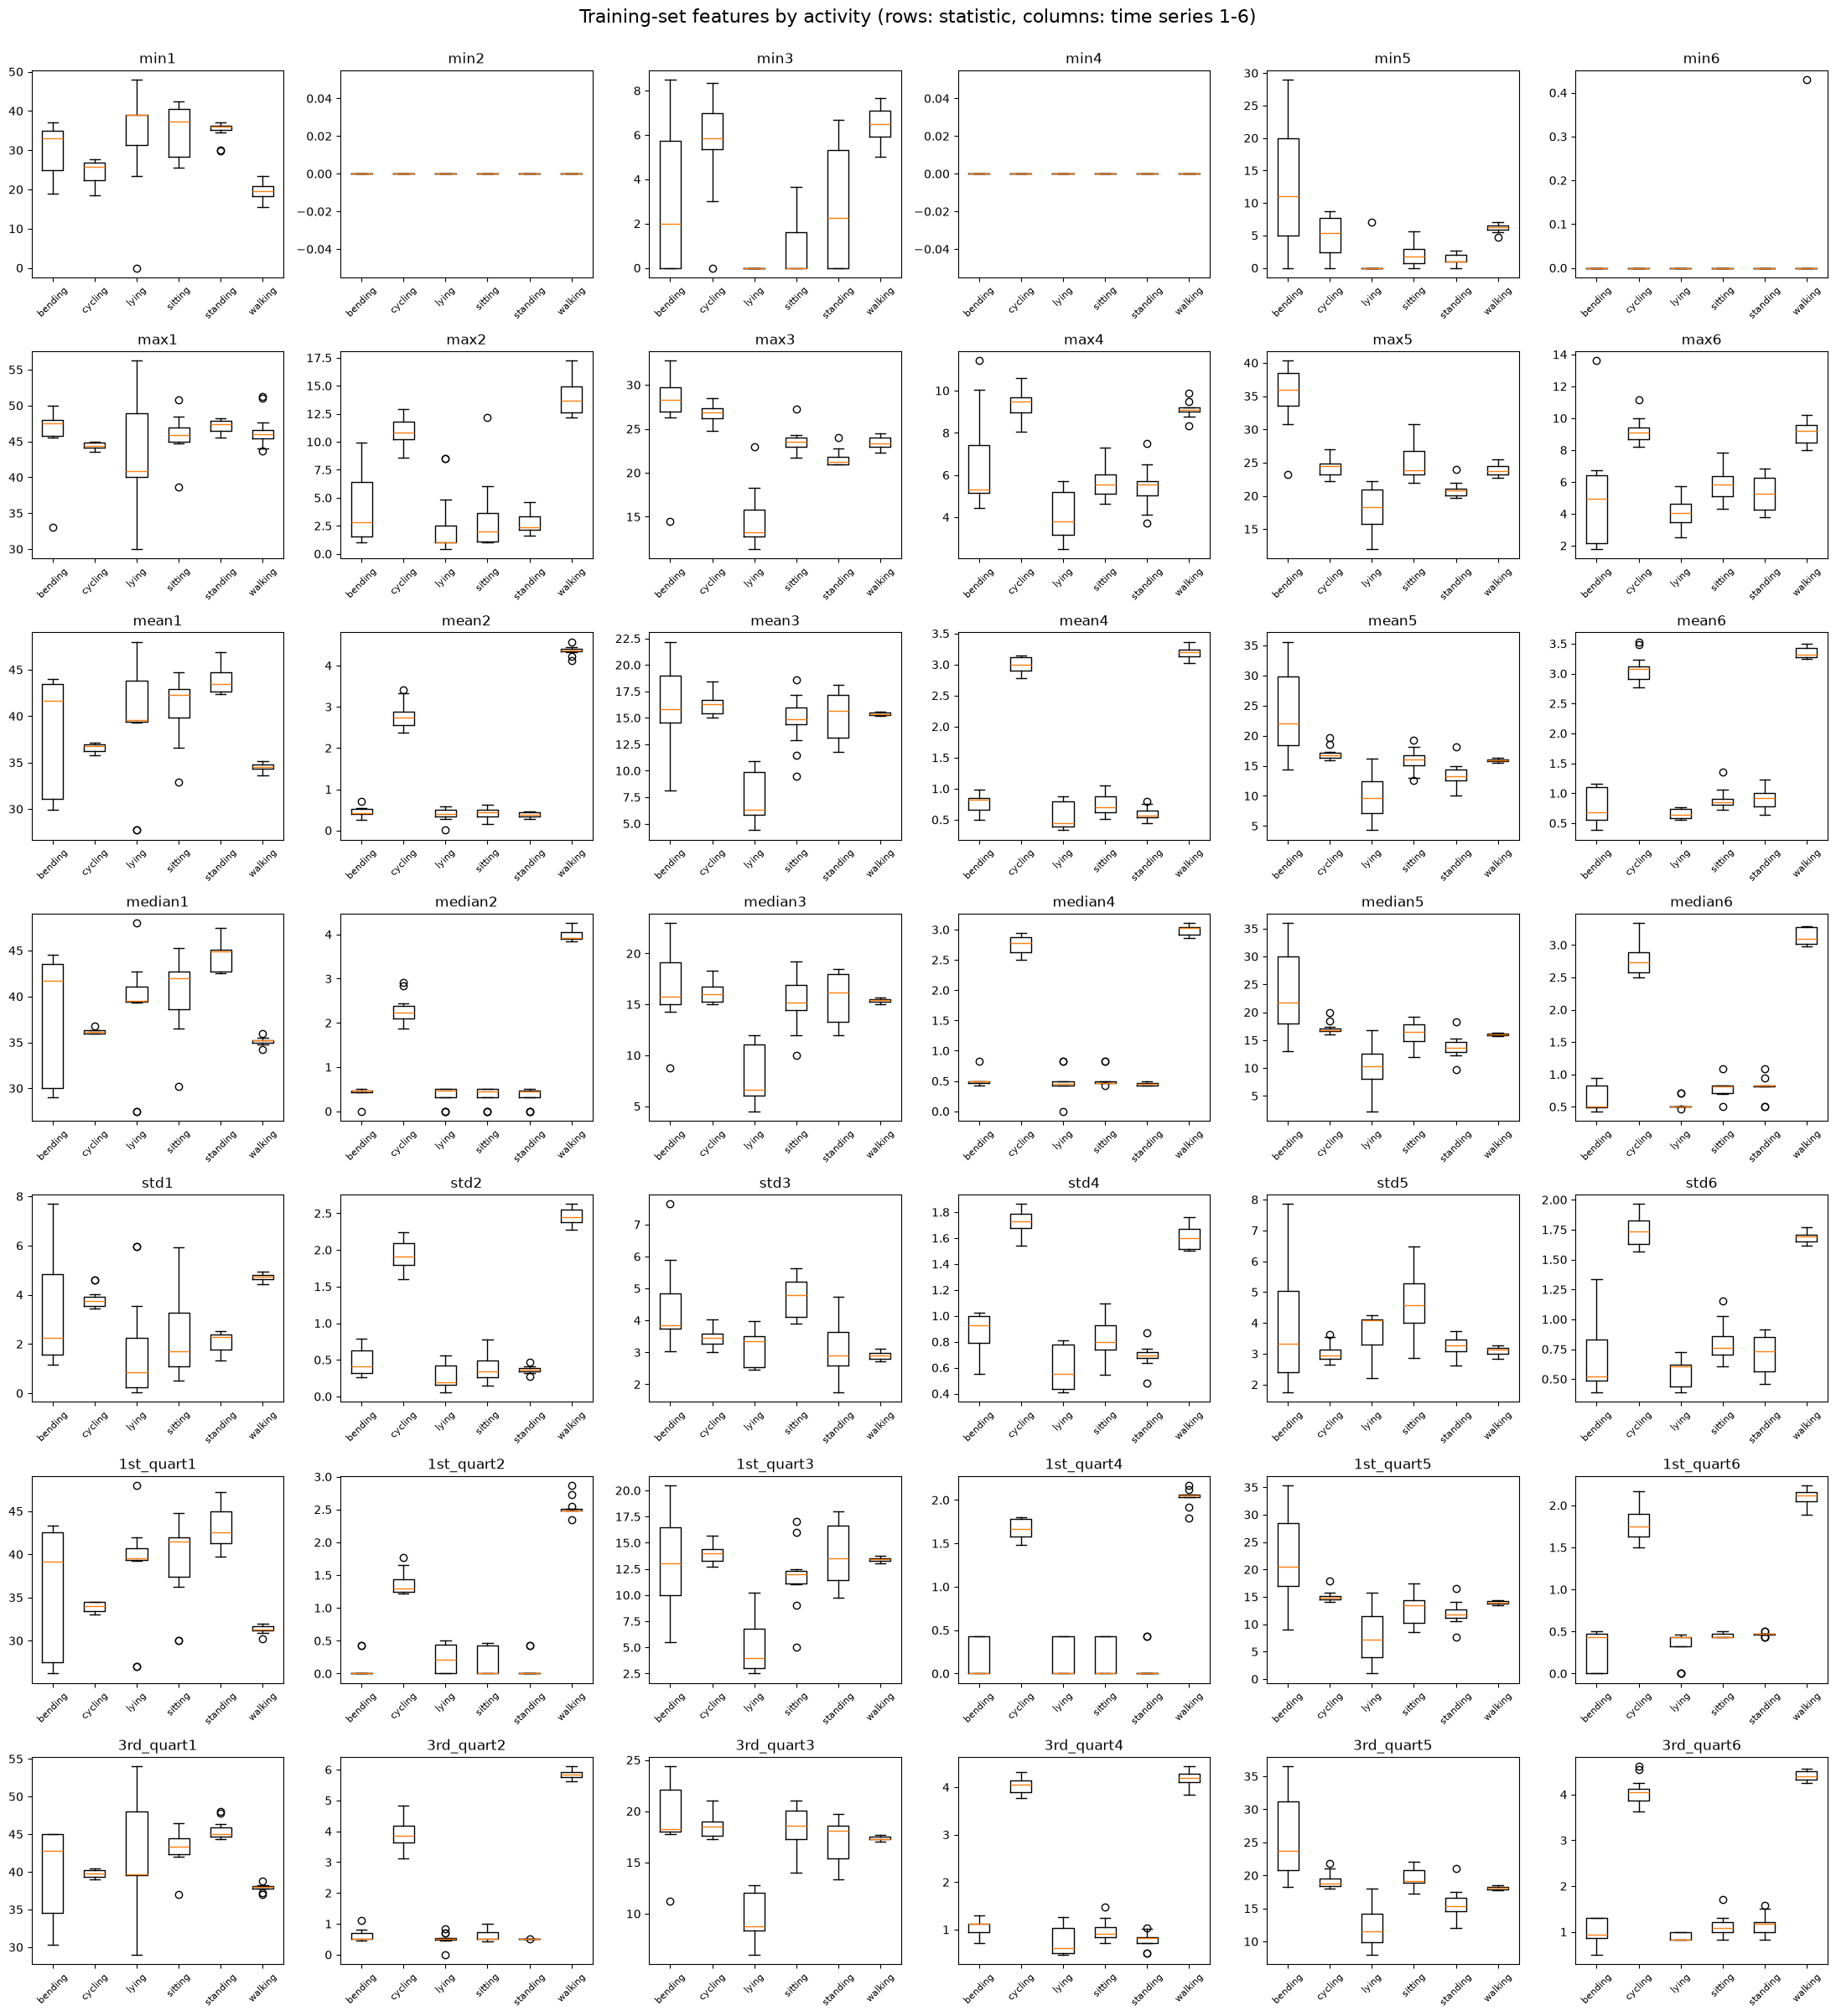

In [6]:
# Question 1civ: boxplots of every feature by activity (training set)
train = features[features["set"] == "train"]
labels = train["activity"].replace({"bending1": "bending", "bending2": "bending"})
activities = sorted(labels.unique())
stats = list(STATS)

fig, axes = plt.subplots(len(stats), len(SERIES), figsize=(22, 24))
for r, stat in enumerate(stats):
    for c in range(len(SERIES)):
        col = f"{stat}{c + 1}"
        ax = axes[r, c]
        ax.boxplot([train.loc[labels == a, col] for a in activities], tick_labels=activities)
        ax.set_title(col)
        ax.tick_params(axis="x", labelrotation=45, labelsize=8)
fig.suptitle("Training-set features by activity (rows: statistic, columns: time series 1-6)", fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

In [7]:
# Average correlation between statistics (same series), across the 6 series
stats = list(STATS)
def avg_corr(a, b):
    r = [features[f"{a}{i}"].corr(features[f"{b}{i}"]) for i in range(1, 7)
         if features[f"{a}{i}"].std() > 0 and features[f"{b}{i}"].std() > 0]
    return np.mean(r)

corr = pd.DataFrame([[avg_corr(a, b) for b in stats] for a in stats], index=stats, columns=stats)
corr.round(2)

,min,max,mean,median,std,1st_quart,3rd_quart
min,1.00,0.37,0.60,0.57,-0.33,0.60,0.53
max,0.37,1.00,0.79,0.76,0.60,0.73,0.81
mean,0.60,0.79,1.00,0.99,0.39,0.98,0.98
median,0.57,0.76,0.99,1.00,0.38,0.98,0.97
std,-0.33,0.60,0.39,0.38,1.00,0.30,0.49
1st_quart,0.60,0.73,0.98,0.98,0.30,1.00,0.95
3rd_quart,0.53,0.81,0.98,0.97,0.49,0.95,1.00


**Selected features: mean, standard deviation, and maximum.**

Box Plots:
- **Figure**: 7 rows for each time-domain feature; 6 columns for each time series in the data; 6 boxplots per plot for each activity (combined both bendings)
- **Analysis**: I am choosing the best 3 rows. We want the rows with the most variation in their box plots in their plots. Min has 3 time series with flat boxplots, so it would not be good for classifying. We also do not want to choose two similar looking rows because that would mean they are more correlated. The other 5 rows have good variation between their plot's boxplots, so we need to rule out highly correlated ones.

Correlation Matrix:
- **Analysis**: The correlation matrix shows that mean, median, 1st_quart, and 3rd_quart are highly correlated. Mean has the least flat boxplots, so we choose mean out of them. That will only leave maximum and std left.

So, we choose mean, standard deviation, and maximum.

## 2. ISLR: 3.7.4

*I collect a set of data (n = 100 observations) containing a single predictor and a quantitative response. I then fit a linear regression model to the data, as well as a separate cubic regression, i.e. $Y = \beta_0 + \beta_1 X + \beta_2 X^2 + \beta_3 X^3 + \epsilon$.*

### (a) Suppose that the true relationship between X and Y is linear, i.e. $Y = \beta_0 + \beta_1 X + \epsilon$. Consider the training residual sum of squares (RSS) for the linear regression, and also the training RSS for the cubic regression. Would we expect one to be lower than the other, would we expect them to be the same, or is there not enough information to tell? Justify your answer.

**The cubic regression will have a lower (or at worst equal) training RSS.** The linear model is a special case of the cubic model (set $\beta_2 = \beta_3 = 0$). Least squares picks the coefficients that minimize training RSS, so the cubic fit can always do at least as well as the linear fit on the training data. Least squares picks the coefficients that minimize training RSS, so the cubic fit can always do at least as well as the linear fit on the training data. The cubic regression will be overfitting the model with the $X^2$ and $X^3$ because it is truly linear.

### (b) Answer (a) using test rather than training RSS.

**We would expect the linear regression to have a lower test RSS.** Because the true relationship is linear, the linear model already has (essentially) no bias. The cubic model is overfit, so it decreased bias and increased variance. This would mean that the test RSS will increase because the model is overfit to the train data.

### (c) Suppose that the true relationship between X and Y is not linear, but we don't know how far it is from linear. Consider the training RSS for the linear regression, and also the training RSS for the cubic regression. Would we expect one to be lower than the other, would we expect them to be the same, or is there not enough information to tell? Justify your answer.

**The cubic regression will have a lower training RSS.** The reasoning is the same as in part (a). Whether the cubic's training RSS is lower does not depend on the true relationship between X and Y: the linear model is a special case of the cubic model ($\beta_2 = \beta_3 = 0$), so the cubic model is more flexible and its training RSS will never be higher than the linear model's. In this case the cubic model also captures more of the real nonlinearity than the linear model.

### (d) Answer (c) using test rather than training RSS.

**There is not enough information to tell.** It depends on how far the true relationship is from linear:
- If it is **far from linear**, the linear model has high bias, and the cubic model's lower bias should outweigh its extra variance. The cubic model will likely have the lower test RSS.
- If it is **only slightly nonlinear**, the linear model's bias is small, and the cubic model's extra variance may outweigh its small reduction in bias. The linear model could have the lower test RSS.